In [1]:
import sys
print(sys.executable)
print(sys.version)

c:\Users\user\M1-1\.venv\.venv\Scripts\python.exe
3.13.14 (tags/v3.13.14:fd17997, Jun 10 2026, 13:03:48) [MSC v.1944 64 bit (AMD64)]


In [ ]:
%pip install pandas

  Using cached pandas-3.1.0-cp313-cp313-win_amd64.whl.metadata (18 kB)
  Using cached numpy-2.5.4-cp313-cp313-win_amd64.whl.metadata (6.6 kB)
Using cached pandas-3.1.0-cp313-cp313-win_amd64.whl (10.7 MB)
Using cached numpy-2.5.4-cp313-cp313-win_amd64.whl (12.6 MB)

   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
!pip install matplotlib

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ------------ --------------------------- 2.9/9.3 MB 15.6 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 25.4 MB/s  0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 47.3 MB/s  0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   ---------------------------------------- 7.3/7.3 MB 70.5 MB/s  0:00:00

   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----------------- ---------------------- 3/7 [fonttools]
   ----------------- ---------------------- 3/7 [fonttools]
   ----------------- ---------------------- 3/7 [fonttools]
   ----------------- ---------------------- 3/7 [fonttools]
   ----------------- ---------------------- 3/7 [fonttools]
   ----------------- -


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd

# 1. 파일 불러오기
file_path = "C:/Users/user/Downloads/changwon_bicycle.csv"

try:
    df = pd.read_csv(file_path, encoding='cp949')
except:
    df = pd.read_csv(file_path, encoding='utf-8')

# 2. 데이터 상단 확인
print("--- 데이터 상단 5행 확인 ---")
display(df.head())

# 3. 데이터 기본 정보 확인
print("\n--- 데이터 요약 정보 ---")
df.info()

# 4. 결측치 확인
print("\n--- 결측치 확인 ---")
print(df.isnull().sum())

--- 데이터 상단 5행 확인 ---


,년월일,이용건수
0,2020-01-01,6062
1,2020-01-02,11636
2,2020-01-03,12464
3,2020-01-04,9596
4,2020-01-05,8037



--- 데이터 요약 정보 ---
<class 'pandas.DataFrame'>
RangeIndex: 912 entries, 0 to 911
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   년월일     912 non-null    str  
 1   이용건수    912 non-null    int64
dtypes: int64(1), str(1)
memory usage: 14.4 KB

--- 결측치 확인 ---
년월일     0
이용건수    0
dtype: int64


--- 변환 후 데이터 정보 ---
<class 'pandas.DataFrame'>
DatetimeIndex: 912 entries, 2020-01-01 to 2022-06-30
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   이용건수    912 non-null    int64
dtypes: int64(1)
memory usage: 14.2 KB


C:\Users\user\AppData\Local\Temp\ipykernel_9012\1128448261.py:5: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.set_index('년월일', inplace=True)


,이용건수
년월일,
2020-01-01,6062
2020-01-02,11636
2020-01-03,12464
2020-01-04,9596
2020-01-05,8037


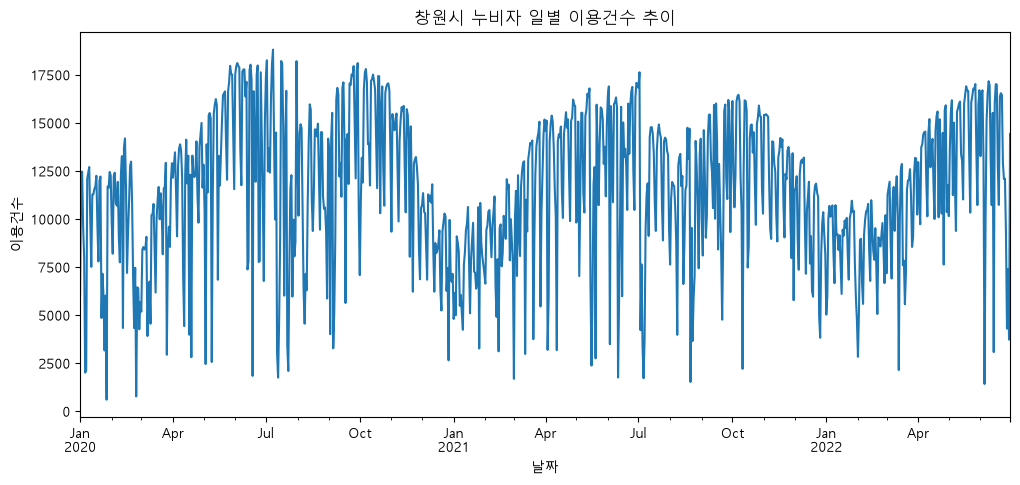

In [4]:
# 1. '년월일' 컬럼을 날짜 형식(datetime)으로 변환
df['년월일'] = pd.to_datetime(df['년월일'])

# 2. '년월일'을 인덱스로 설정 
df.set_index('년월일', inplace=True)

# 3. 결과 확인
print("--- 변환 후 데이터 정보 ---")
df.info()
display(df.head())

# 4. 간단하게 그래프 그려보기
import matplotlib.pyplot as plt

# 한글 깨짐 방지 설정 
plt.rc('font', family='Malgun Gothic') 

df['이용건수'].plot(figsize=(12, 5), title='창원시 누비자 일별 이용건수 추이')
plt.xlabel('날짜')
plt.ylabel('이용건수')
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_9012\511852894.py:5: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df['요일'] = df.index.dayofweek # 0:월, 1:화 ... 6:일


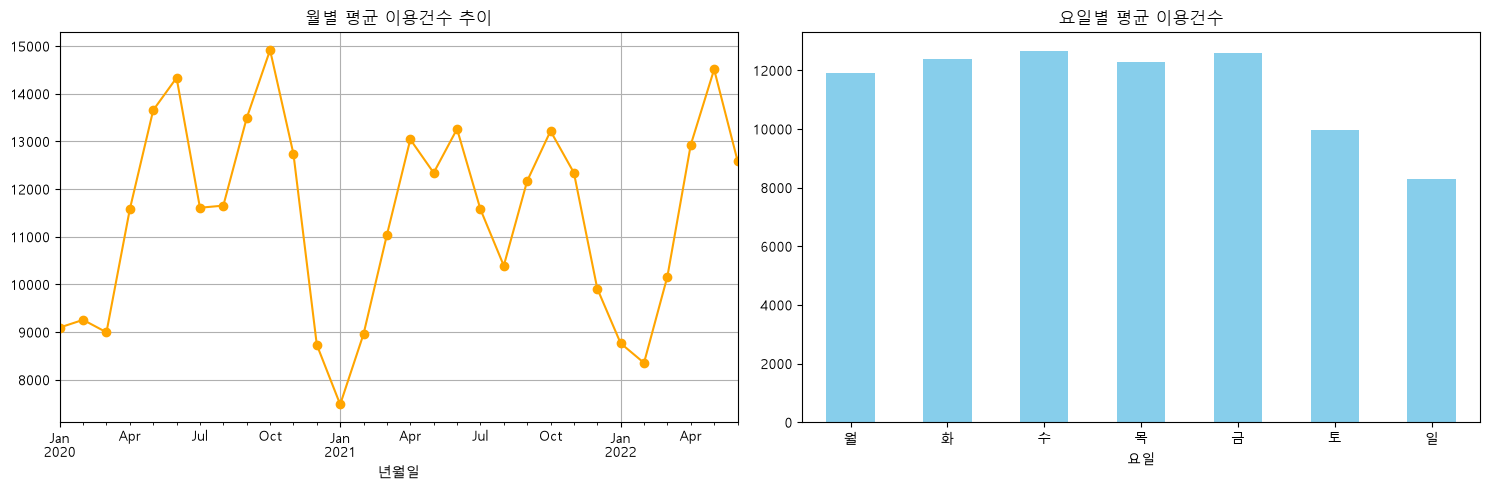

In [5]:
# 1. 월별 평균 이용건수 계산 (데이터를 부드럽게 보기)
df_monthly = df['이용건수'].resample('ME').mean()

# 2. 요일별 평균 이용건수 계산 (평일 vs 주말)
df['요일'] = df.index.dayofweek # 0:월, 1:화 ... 6:일
df_weekly = df.groupby('요일')['이용건수'].mean()

# 시각화
plt.figure(figsize=(15, 5))

# 첫 번째 그래프: 월별 추이
plt.subplot(1, 2, 1)
df_monthly.plot(kind='line', marker='o', color='orange')
plt.title('월별 평균 이용건수 추이')
plt.grid(True)

# 두 번째 그래프: 요일별 평균 (0=월, 6=일)
plt.subplot(1, 2, 2)
df_weekly.plot(kind='bar', color='skyblue')
plt.title('요일별 평균 이용건수')
plt.xticks(range(7), ['월', '화', '수', '목', '금', '토', '일'], rotation=0)

plt.tight_layout()
plt.show()

In [6]:
%pip install statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ------ --------------------------------- 1.8/11.3 MB 10.2 MB/s eta 0:00:01
   ------------------------- -------------- 7.1/11.3 MB 18.8 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 23.6 MB/s  0:00:00
   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   ------------------ --------------------- 16.5/36.6 MB 79.2 MB/s eta 0:00:01
   -------------------------------- ------- 29.4/36.6 MB 69.5 MB/s eta 0:00:01
   ---------------------------------------- 36.6/36.6 MB 62.4 MB/s  0:00:00

   ----- ---------------------------------- 1/7 [scipy]
   ----- ---------------------------------- 1/7 [scipy]
   ----- ---------------------------------- 1/7 [scipy]
   ----- ---------------------------------- 1/7 [scipy]
   ----- ---------------------------------- 1/7 [scipy]
   ----- ---------------------------------- 1/7 [scipy]
   ----- ---------------------------------- 1/7 [scipy]
 


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


c:\Users\user\M1-1\.venv\.venv\Lib\site-packages\statsmodels\tsa\seasonal\_seasonal.py:403: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.tight_layout()
c:\Users\user\M1-1\.venv\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


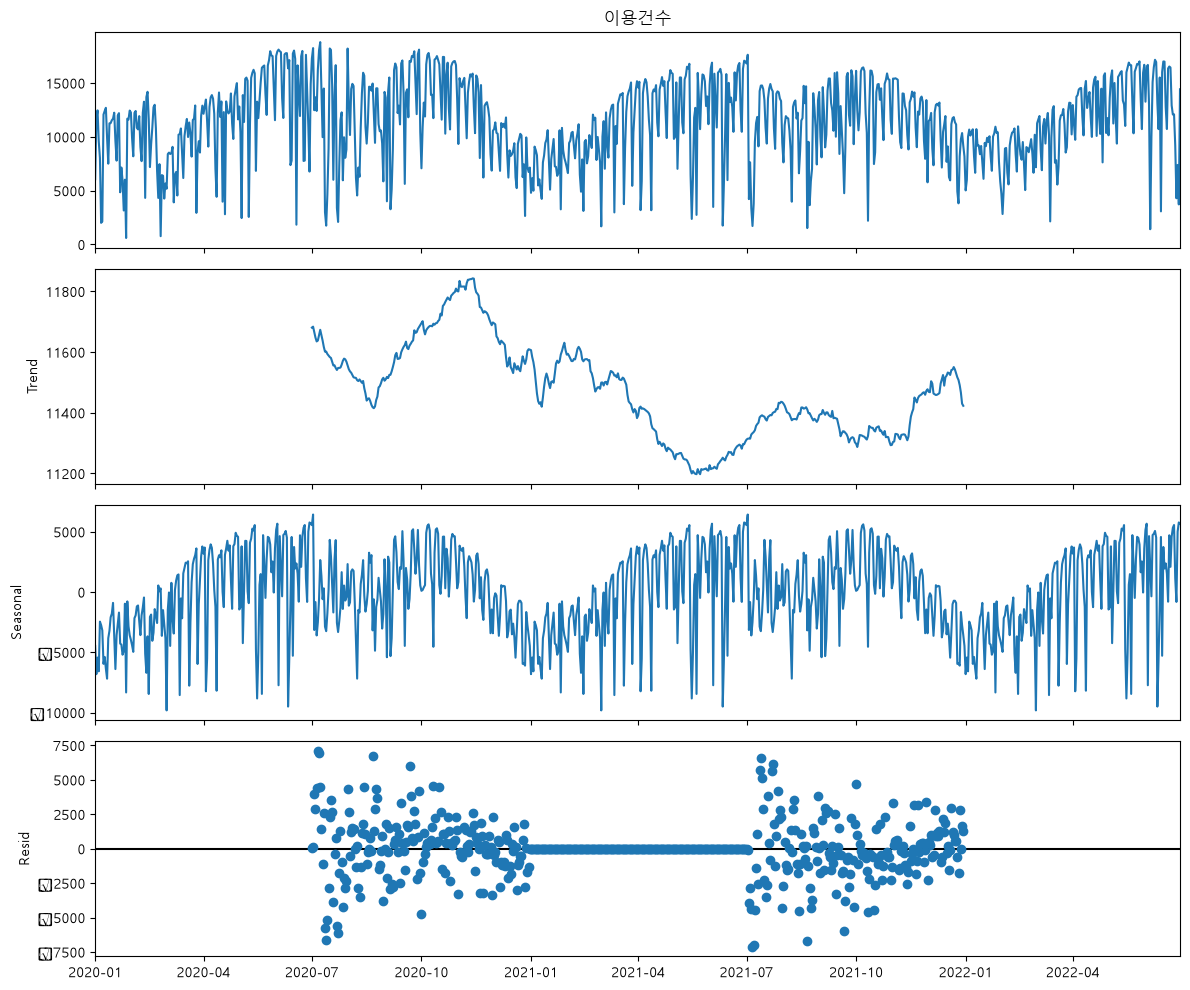

In [6]:
from statsmodels.tsa.seasonal import seasonal_decompose

# 시계열 분해 (모델: 가법 모델(additive), 주기: 365일)
# 일별 데이터이므로 period를 365로 설정하여 연간 패턴을 봅니다.
result = seasonal_decompose(df['이용건수'], model='additive', period=365)

# 그래프 그리기
plt.rcParams['figure.figsize'] = (12, 10)
result.plot()
plt.show()

c:\Users\user\M1-1\.venv\.venv\Lib\site-packages\statsmodels\tsa\seasonal\_seasonal.py:403: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.tight_layout()
c:\Users\user\M1-1\.venv\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


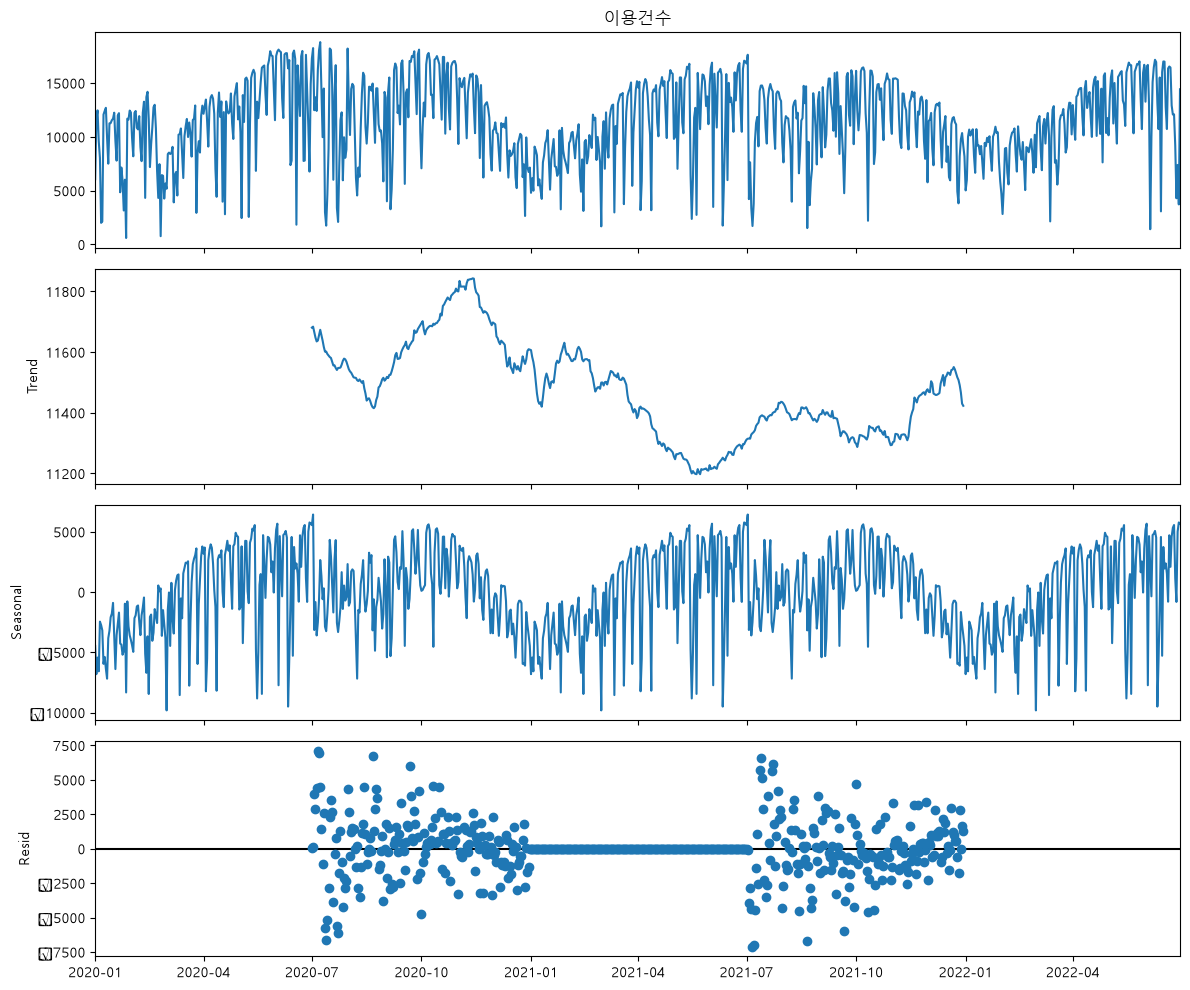

In [7]:
from statsmodels.tsa.seasonal import seasonal_decompose

# 시계열 분해 (모델: 가법 모델(additive), 주기: 7일)
# 일별 데이터이므로 period를 7로 설정하여 연간 패턴을 봅니다.
result_weekly = seasonal_decompose(df['이용건수'], model='additive', period=7)

# 그래프 그리기
plt.rcParams['figure.figsize'] = (12, 10)
result.plot()
plt.show()

c:\Users\user\M1-1\.venv\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


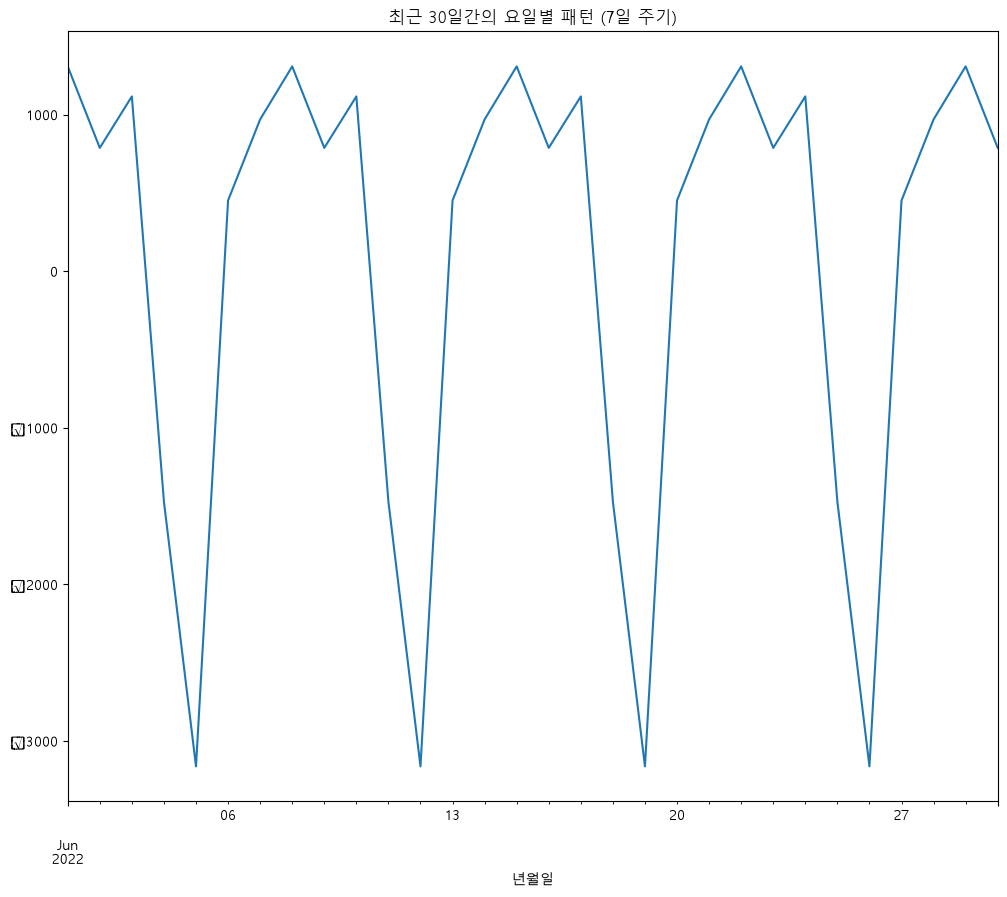

In [8]:
# 딱 최근 1개월(30일) 데이터만 잘라서 시각화해보기
result_weekly.seasonal[-30:].plot()
plt.title("최근 30일간의 요일별 패턴 (7일 주기)")
plt.show()

## 데이터를 통해 하고 싶은 질문 3가지

### 질문 1: 창원 누비자는 '출퇴근용'일까 '나들이용'일까

- 분석 방법: 요일별 평균 이용건수 비교 (이미 살짝 해봤죠!)
- 기대 효과: 평일 수요가 압도적이라면 '대중교통 보조 수단'으로서의 가치를 증명할 수 있고, 주말이 높다면 '여가 서비스'로서의 성격을 강조할 수 있습니다.
- 연결된 기법: 요일별 집계, 시계열 분해(Seasonal)

C:\Users\user\AppData\Local\Temp\ipykernel_9012\2764627176.py:5: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  weekday_stats = df.groupby(df.index.dayofweek)['이용건수'].mean()


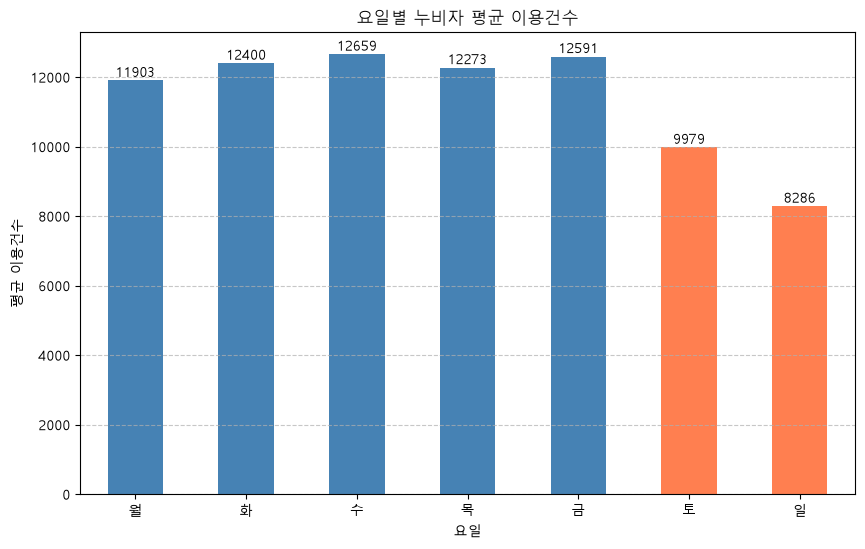

✅ 평일 평균: 12365건
✅ 주말 평균: 9132건
✅ 평일이 주말보다 약 35.4% 더 많이 이용됨


In [9]:
# 요일 이름 설정을 위한 리스트 (월~일)
weekday_names = ['월', '화', '수', '목', '금', '토', '일']

# 요일별 평균 이용건수 계산 (0=월, 6=일)
weekday_stats = df.groupby(df.index.dayofweek)['이용건수'].mean()
weekday_stats.index = weekday_names

# 시각화
plt.figure(figsize=(10, 6))
colors = ['steelblue' if x < 5 else 'coral' for x in range(7)] # 평일은 파랑, 주말은 주황
weekday_stats.plot(kind='bar', color=colors, rot=0)

plt.title('요일별 누비자 평균 이용건수')
plt.xlabel('요일')
plt.ylabel('평균 이용건수')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 수치 표시
for i, v in enumerate(weekday_stats):
    plt.text(i, v + 100, f"{v:.0f}", ha='center')

plt.show()

# 평일 vs 주말 평균 비교
weekday_avg = weekday_stats[:5].mean()
weekend_avg = weekday_stats[5:].mean()
print(f"✅ 평일 평균: {weekday_avg:.0f}건")
print(f"✅ 주말 평균: {weekend_avg:.0f}건")
print(f"✅ 평일이 주말보다 약 {((weekday_avg - weekend_avg) / weekend_avg * 100):.1f}% 더 많이 이용됨")

### 질문 2: "계절(날씨)의 변화가 이용량에 미치는 '정량적' 영향은 어느 정도일까?"
- 분석 방법: 월별 이용건수 합계 및 시계열 분해의 Seasonal 데이터 수치 확인
- 기대 효과: 가장 많이 타는 달(예: 5월)과 가장 안 타는 달(예: 1월)의 차이를 수치화하여, 계절별 운영 전략(예: 겨울철 정비 집중 기간 설정)의 근거를 마련합니다.
- 연결된 기법: 월별 집계, 시계열 분해(Seasonal)

c:\Users\user\M1-1\.venv\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


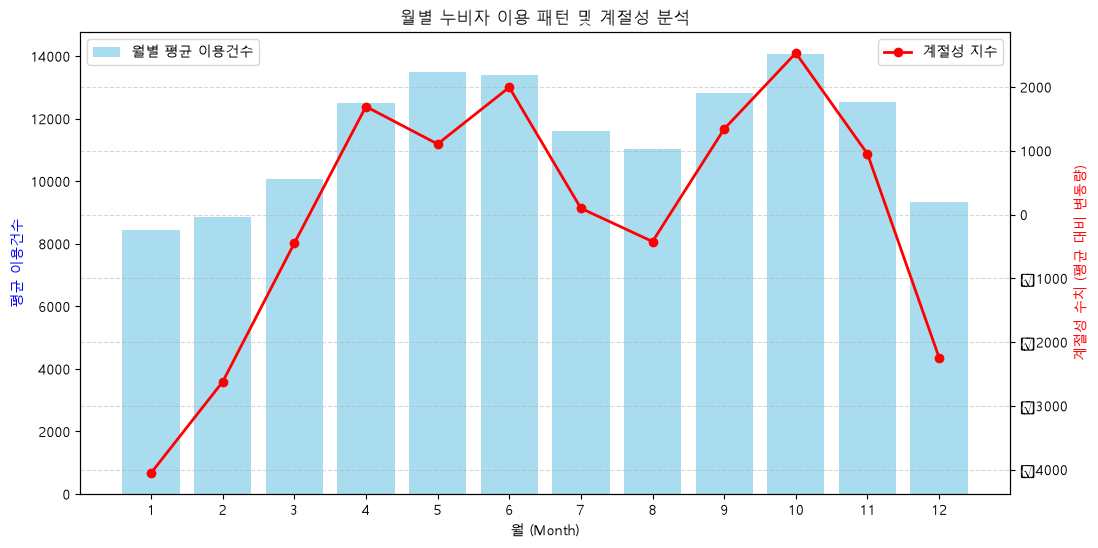

📊 분석 결과:
- 가장 많이 타는 달: 10월 (평균 14066건)
- 가장 적게 타는 달: 1월 (평균 8446건)
- 두 달의 차이: 약 5620건
- 1월 대비 10월 이용량 증가율: 66.5%


In [10]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. 월별 평균 이용건수 계산 (전체 기간 동안의 월별 평균)
# 2020~2022년의 모든 1월, 모든 2월... 의 평균을 구합니다.
monthly_stats = df.groupby(df.index.month)['이용건수'].mean()

# 2. 시계열 분해 결과에서 계절성(Seasonal) 성분만 추출
# 아까 만든 result 객체에서 seasonal 성분을 가져와 월별로 평균을 냅니다.
seasonal_component = result.seasonal.groupby(result.seasonal.index.month).mean()

# --- 시각화 ---
fig, ax1 = plt.subplots(figsize=(12, 6))

# 왼쪽 축: 실제 이용건수 막대 그래프
ax1.bar(monthly_stats.index, monthly_stats.values, color='skyblue', alpha=0.7, label='월별 평균 이용건수')
ax1.set_xlabel('월 (Month)')
ax1.set_ylabel('평균 이용건수', color='blue')
ax1.set_xticks(range(1, 13))

# 오른쪽 축: 계절성 지수 (평균으로부터 얼마나 더 타거나 덜 타는지)
ax2 = ax1.twinx()
ax2.plot(seasonal_component.index, seasonal_component.values, color='red', marker='o', linewidth=2, label='계절성 지수')
ax2.set_ylabel('계절성 수치 (평균 대비 변동량)', color='red')

plt.title('월별 누비자 이용 패턴 및 계절성 분석')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

# --- 정량적 수치 출력 ---
max_month = monthly_stats.idxmax()
min_month = monthly_stats.idxmin()
diff = monthly_stats.max() - monthly_stats.min()
increase_rate = (diff / monthly_stats.min()) * 100

print(f"📊 분석 결과:")
print(f"- 가장 많이 타는 달: {max_month}월 (평균 {monthly_stats.max():.0f}건)")
print(f"- 가장 적게 타는 달: {min_month}월 (평균 {monthly_stats.min():.0f}건)")
print(f"- 두 달의 차이: 약 {diff:.0f}건")
print(f"- {min_month}월 대비 {max_month}월 이용량 증가율: {increase_rate:.1f}%")

### 질문 3: "2020년부터 2022년까지 누비자 이용은 '성장'하고 있을까, '쇠퇴'하고 있을까?"
- 분석 방법: 7일/30일 이동평균(Moving Average) 계산 및 시계열 분해의 Trend 분석
- 기대 효과: 일별 변동(노이즈)을 제거하고 전체적인 흐름을 파악합니다. 코로나19 거리두기 해제나 다른 교통수단 도입 등이 영향을 주었는지 가설을 세워볼 수 있습니다.
- 연결된 기법: 이동평균(Moving Average), 시계열 분해(Trend)

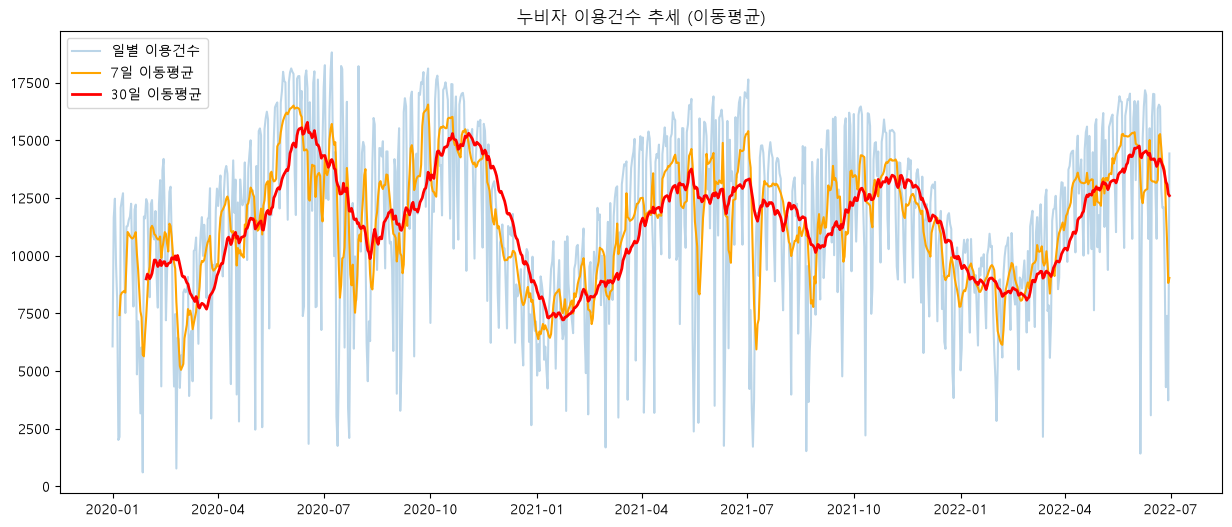

In [11]:
# 이동평균 계산
df['7일_이동평균'] = df['이용건수'].rolling(window=7).mean()
df['30일_이동평균'] = df['이용건수'].rolling(window=30).mean()

# 시각화
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))
plt.plot(df.index, df['이용건수'], alpha=0.3, label='일별 이용건수') # 원본은 흐리게
plt.plot(df.index, df['7일_이동평균'], label='7일 이동평균', color='orange')
plt.plot(df.index, df['30일_이동평균'], label='30일 이동평균', color='red', linewidth=2)

plt.title('누비자 이용건수 추세 (이동평균)')
plt.legend()
plt.show()

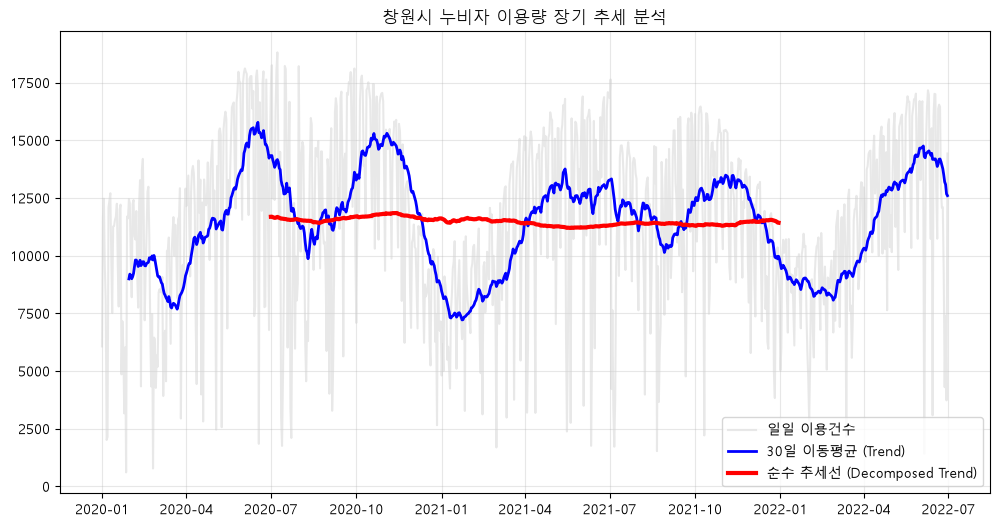

📈 분석 결과:
- 분석 시작 시점 추세: 약 11681건
- 분석 종료 시점 추세: 약 11423건
- 전체 기간 동안의 추세 변화율: -2.2%


In [12]:
# 시계열 분해 결과에서 추세(Trend) 데이터 시각화
plt.figure(figsize=(12, 6))

# 1. 실제 데이터 (연하게)
plt.plot(df.index, df['이용건수'], color='lightgray', alpha=0.5, label='일일 이용건수')

# 2. 30일 이동평균 (흐름 파악용)
plt.plot(df.index, df['이용건수'].rolling(window=30).mean(), color='blue', linewidth=2, label='30일 이동평균 (Trend)')

# 3. 시계열 분해에서 얻은 Trend (순수 추세)
plt.plot(result.trend.index, result.trend.values, color='red', linewidth=3, label='순수 추세선 (Decomposed Trend)')

plt.title('창원시 누비자 이용량 장기 추세 분석')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 시작 시점과 종료 시점의 추세값 비교
trend_start = result.trend.dropna().iloc[0]
trend_end = result.trend.dropna().iloc[-1]
growth_rate = (trend_end - trend_start) / trend_start * 100

print(f"📈 분석 결과:")
print(f"- 분석 시작 시점 추세: 약 {trend_start:.0f}건")
print(f"- 분석 종료 시점 추세: 약 {trend_end:.0f}건")
print(f"- 전체 기간 동안의 추세 변화율: {growth_rate:+.1f}%")

### 두 가지 반례 분석

##### 1. 집계 단위의 변화 (일간 vs 월간)

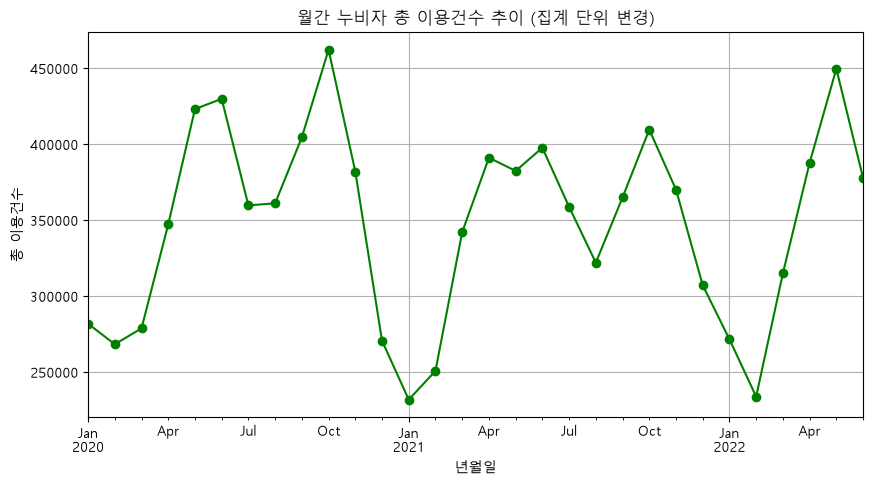

일간 분석에서는 보이지 않던 월별 총량의 '계단식 상승'이 더 뚜렷하게 보이나요?


In [14]:
# 월간 단위로 재집계 (Monthly Resampling)
monthly_df = df['이용건수'].resample('ME').sum()

plt.figure(figsize=(10, 5))
monthly_df.plot(marker='o', color='green')
plt.title('월간 누비자 총 이용건수 추이 (집계 단위 변경)')
plt.ylabel('총 이용건수')
plt.grid(True)
plt.show()

print(f"일간 분석에서는 보이지 않던 월별 총량의 '계단식 상승'이 더 뚜렷하게 보이나요?")

##### 2. 기간의 분리 (2020년 vs 2021년 비교)

In [15]:
# 연도별 데이터 분리
df_2020 = df[df.index.year == 2020]
df_2021 = df[df.index.year == 2021]

print(f"2020년 평균 이용건수: {df_2020['이용건수'].mean():.0f}건")
print(f"2021년 평균 이용건수: {df_2021['이용건수'].mean():.0f}건")

# 연도별 요일 패턴 비교
df_2020_weekday = df_2020.groupby(df_2020.index.dayofweek)['이용건수'].mean()
df_2021_weekday = df_2021.groupby(df_2021.index.dayofweek)['이용건수'].mean()

# (이후 시각화 코드는 생략 가능하나, 수치 비교는 필수)

2020년 평균 이용건수: 11669건
2021년 평균 이용건수: 11315건


C:\Users\user\AppData\Local\Temp\ipykernel_9012\1939550530.py:9: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df_2020_weekday = df_2020.groupby(df_2020.index.dayofweek)['이용건수'].mean()
C:\Users\user\AppData\Local\Temp\ipykernel_9012\1939550530.py:10: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df_2021_weekday = df_2021.groupby(df_2021.index.dayofweek)['이용건수'].mean()


##### 연도별로 쪼개봐도 평일이 주말보다 많은 패턴은 유지되는가?

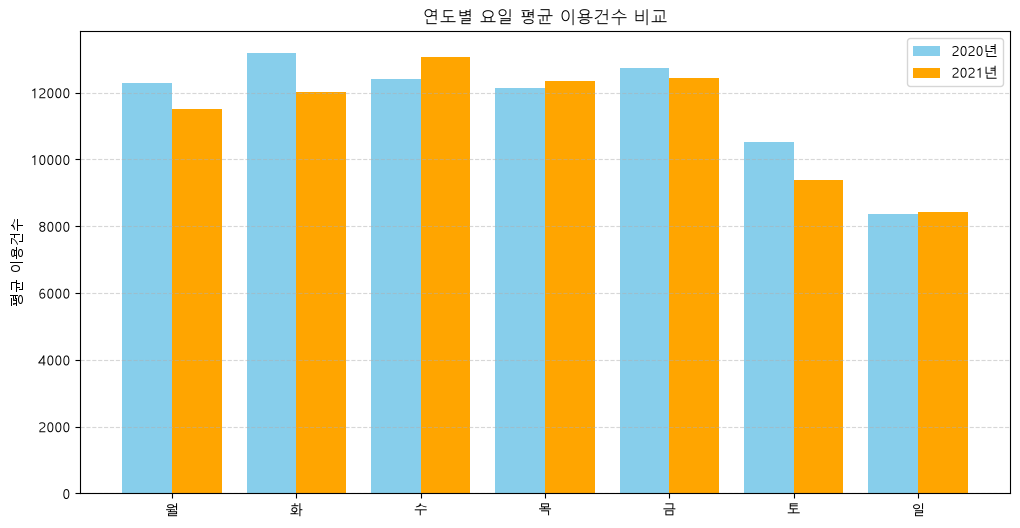

In [16]:
import matplotlib.pyplot as plt
import pandas as pd

# 데이터 준비 (Warning 해결: day_of_week 사용)
df_2020 = df[df.index.year == 2020]
df_2021 = df[df.index.year == 2021]

weekday_2020 = df_2020.groupby(df_2020.index.day_of_week)['이용건수'].mean()
weekday_2021 = df_2021.groupby(df_2021.index.day_of_week)['이용건수'].mean()

# 시각화
plt.figure(figsize=(12, 6))
x = range(7)
weekday_names = ['월', '화', '수', '목', '금', '토', '일']

plt.bar([i - 0.2 for i in x], weekday_2020, width=0.4, label='2020년', color='skyblue')
plt.bar([i + 0.2 for i in x], weekday_2021, width=0.4, label='2021년', color='orange')

plt.xticks(x, weekday_names)
plt.title('연도별 요일 평균 이용건수 비교')
plt.ylabel('평균 이용건수')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()